# Single-Call Hedging: Neural Networks and Heston Benchmarks

### Overview:
We attempt to hedge one European call in a simulated Heston market with transaction costs. We compare paper-style networks trained on static stock paths generated prior to training with our networks trained on stock paths fresh batches generated in-line during training. For both the paper and our network, we run train once in the case where we trading stocks alone and once in the case where we may also trade variance claims. We evaluate the CVaR and entropic risks for each model, and compare the trained strategies with classical Heston hedges. 

We also compare the paper's and our stock-only model trained in the cost-free regime to the Heston Model's hedging strategy; this allows us to assess if the neural networks can approximate the optimal strategy and whether or not the optimal strategy is close to the Heston Hedge.  

# Comparison of Paper's and Our Network with Transaction Costs

We hedge one European call over 30 trading days in a simulated Heston market, where both stock price and variance change over time.

We compare two network designs, each with stock-only trading or stock plus a variance claim. All networks observe variance, but the “stock only” cases restricts what instruments they can trade.

The paper-style networks train from a fixed pool of paths. Our networks receive fresh simulated batches at each iteration. Validation selects the final policies, and 8,192 separate test paths measure their performance.


## Model Setup 

In [6]:
from scripts.general_nn import generalNN
from scripts import plots
import importlib

from dataclasses import replace

from scripts.general_nn import generalNN
from scripts.settings import Settings
from scripts import plots


# Use a small training budget for this first experiment.
settings = Settings(
    warmup_updates=100,
    continuation_updates=100,
    number_of_replicates=1,

    # Check validation performance every 25 training updates.
    validation_interval=25,

    # Set the sizes of the calibration, validation, and test datasets.
    normalization_size=2048,
    validation_size=2048,
    test_size=8192,

    # Used only if we choose to train from a fixed dataset.
    static_training_size=25600,
)


In [ ]:
# dynamic_data:
# True: generate fresh training batches during each iteration.
# False: sample batches from one fixed training dataset.

# Create a new paper-style model that trades using stock and the variance information.
paper = generalNN(
    method="paper",
    settings=settings,
    dynamic_data=False,
    name="Paper network: stock + variance",
)

# Copy the settings and disable trading using variance.
control_settings = replace(settings, trade_variance=False)

# Create a new paper-style model restricted to stock trading.
control = generalNN(
    method="paper",
    settings=control_settings,
    dynamic_data=False,
)

# Create a new model using our smaller network design.
ours = generalNN(
    method="ours",
    settings=settings,
    dynamic_data=True,
    name="Our network: stock only",
)


# Keep our settings, but use the same instruments as the full reference.
settings_with_variance = replace(
    ours.settings,
    instruments=paper.settings.instruments,
    trade_variance=True,
)

ours_variance = generalNN(
    method="ours",
    settings=settings_with_variance,
    dynamic_data=ours.dynamic_data,
    name="Our network: stock + variance",
)

## Model Training

In [8]:
# Train and evaluate each newly created model.
for model in (paper, control, ours, ours_variance):

    print(f"\nTraining: {model.name}")

    # Prepare the training data and fit the hedging policies.
    model.train(verbose=True)

    # Measure the trained policies on separate test paths.
    model.evaluate()


Training: Paper network: stock + variance
paper_full_0_warmup: update 0, validation risk 6.30455
paper_full_0_warmup: update 100, validation risk 2.63928
paper_full_0_CVaR: update 0, validation risk 2.63576
paper_full_0_CVaR: update 100, validation risk 2.44172
paper_full_0_Entropic: update 0, validation risk 5.79792
paper_full_0_Entropic: update 100, validation risk 2.26705

Training: Paper style: stock only
paper_stock_0_warmup: update 0, validation risk 5.21149
paper_stock_0_warmup: update 100, validation risk 2.96685
paper_stock_0_CVaR: update 0, validation risk 2.93904
paper_stock_0_CVaR: update 100, validation risk 2.75610
paper_stock_0_Entropic: update 0, validation risk 5.93665
paper_stock_0_Entropic: update 100, validation risk 4.83141

Training: Our network: stock only
ours_0_warmup: update 0, validation risk 4.15072
ours_0_warmup: update 100, validation risk 2.80630
ours_0_CVaR: update 0, validation risk 2.80448
ours_0_CVaR: update 100, validation risk 2.80386
ours_0_Entrop

## Display Results

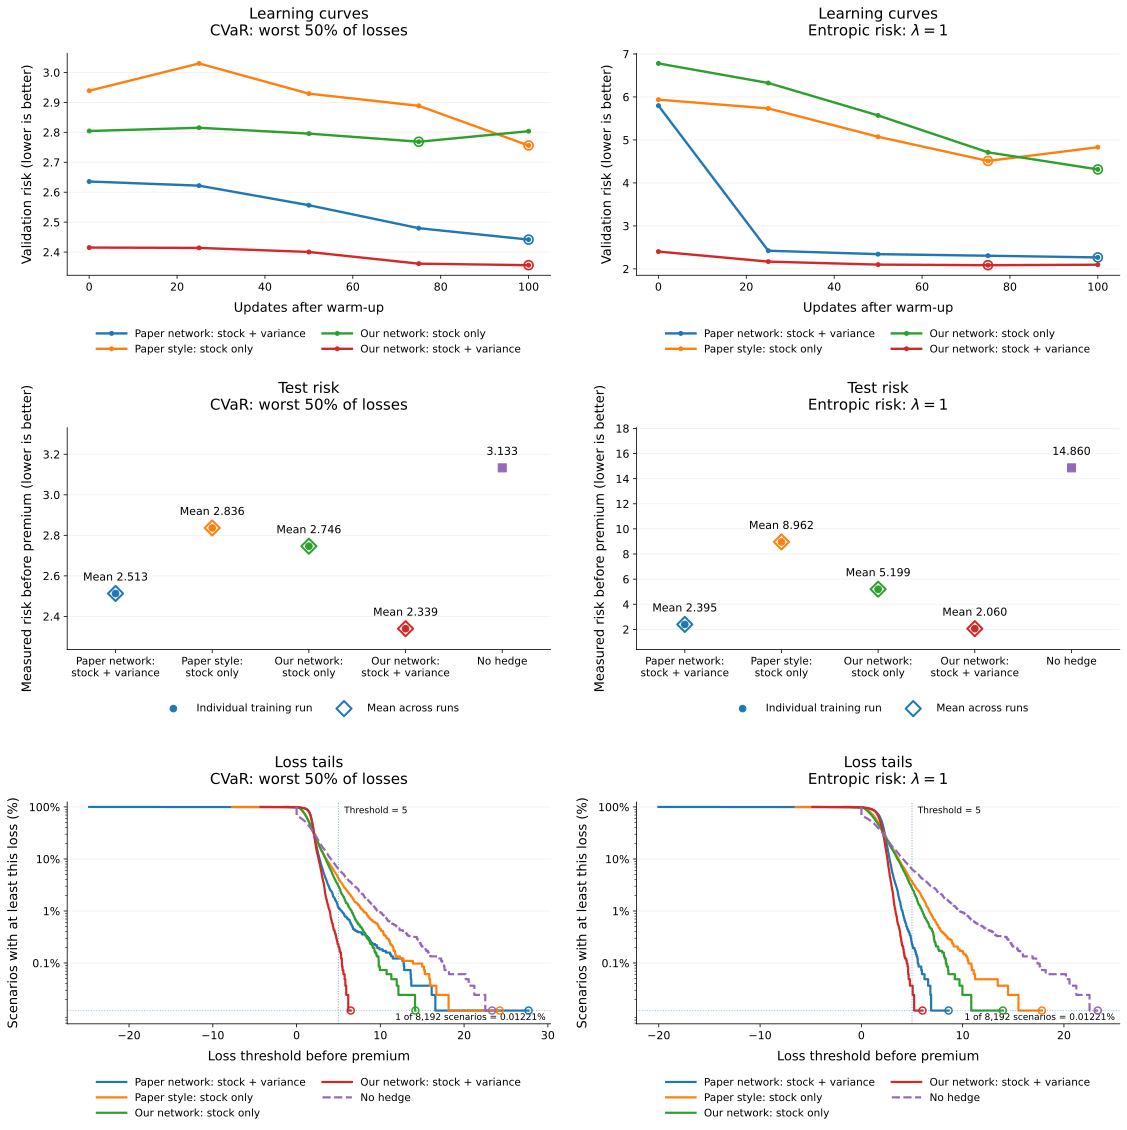

In [9]:
experiments = [paper, control, ours, ours_variance]
plots.plot_results_grid(experiments)

## Comments
**<u>Learning curves:</u>**
These curves show validation risk during training after the initial warm-up. Lower values are better. CVaR training focuses on the worst half of losses, while entropic training penalizes large losses exponentially.

The curves can fluctuate. This short training run does not establish that the networks have converged.

**<u>Test performance:</u>**
These graphs measure losses before receiving the option premium. Lower risk is better. “No hedge” means paying the option payoff without any trading gains.

In this saved run, adding the variance claim lowers measured risk for both network designs. Among the four neural configurations, our stock-plus-variance network has the lowest risk under both objectives.

Architecture and training-data mode change together, so these results do not isolate the benefit of fresh training data. The Heston benchmarks are compared later.

**<u>Large losses:</u>**
At each loss threshold, the curve shows the fraction of test scenarios with a loss at least that large. A lower curve at the same threshold means fewer such losses.

The far ends of the curves depend on very few scenarios. A better 50%-CVaR score does not necessarily mean a smaller worst loss or better protection in the worst 1% of cases.

# P&L Comparison in Cost-free Regime: Heston Hedge versus Model Hedge

Every strategy receives the same option premium, approximately 1.692. Final P&L equals this premium minus the hedging loss, including transaction costs. Positive values represent profits.

Both panels show the same observations: the left shows the full range and the right zooms into the centre. A positive peak alone does not establish better hedging.

In this saved run, our network has the lowest CVaR loss: 2.722, compared with 2.921 for the paper-style network and 3.051 for Heston. Thus, our network has the highest average P&L in the worst half of scenarios on this test sample.`

## Model Setup - No Transaction Cost

In [16]:
from scripts.general_nn import generalNN
from scripts import plots
import importlib

from dataclasses import replace

from scripts.general_nn import generalNN
from scripts.settings import Settings
from scripts import plots


# Use a small training budget for this first experiment.
settings = Settings(
    warmup_updates=100,
    continuation_updates=100,
    number_of_replicates=1,

    # Check validation performance every 25 training updates.
    validation_interval=25,

    # Set the sizes of the calibration, validation, and test datasets.
    normalization_size=2048,
    validation_size=2048,
    test_size=8192,

    # Used only if we choose to train from a fixed dataset.
    static_training_size=25600,

    # No Costs
    cost_rate=0,
)


In [17]:
# dynamic_data:
# True: generate fresh training batches during each iteration.
# False: sample batches from one fixed training dataset.

# Create a new paper-style model that trades using stock and the variance information.
paper = generalNN(
    method="paper",
    settings=settings,
    dynamic_data=False,
    name="Paper network: stock + variance",
)

# Copy the settings and disable trading using variance.
control_settings = replace(settings, trade_variance=False)

# Create a new paper-style model restricted to stock trading.
control = generalNN(
    method="paper",
    settings=control_settings,
    dynamic_data=False,
)

# Create a new model using our smaller network design.
ours = generalNN(
    method="ours",
    settings=settings,
    dynamic_data=True,
    name="Our network: stock only",
)


# Keep our settings, but use the same instruments as the full reference.
settings_with_variance = replace(
    ours.settings,
    instruments=paper.settings.instruments,
    trade_variance=True,
)

ours_variance = generalNN(
    method="ours",
    settings=settings_with_variance,
    dynamic_data=ours.dynamic_data,
    name="Our network: stock + variance",
)

## Model Training - No Transaction Cost

In [18]:
# Train and evaluate each newly created model.
for model in (paper, control, ours, ours_variance):

    print(f"\nTraining: {model.name}")

    # Prepare the training data and fit the hedging policies.
    model.train(verbose=True)

    # Measure the trained policies on separate test paths.
    model.evaluate()


Training: Paper network: stock + variance
paper_full_0_warmup: update 0, validation risk 5.05930
paper_full_0_warmup: update 100, validation risk 2.51236
paper_full_0_CVaR: update 0, validation risk 2.50967
paper_full_0_CVaR: update 100, validation risk 2.25858
paper_full_0_Entropic: update 0, validation risk 7.83070
paper_full_0_Entropic: update 100, validation risk 3.68946

Training: Paper style: stock only
paper_stock_0_warmup: update 0, validation risk 4.08791
paper_stock_0_warmup: update 100, validation risk 2.74388
paper_stock_0_CVaR: update 0, validation risk 2.68824
paper_stock_0_CVaR: update 100, validation risk 2.55584
paper_stock_0_Entropic: update 0, validation risk 8.20861
paper_stock_0_Entropic: update 100, validation risk 7.75456

Training: Our network: stock only
ours_0_warmup: update 0, validation risk 3.35969
ours_0_warmup: update 100, validation risk 2.65080
ours_0_CVaR: update 0, validation risk 2.65080
ours_0_CVaR: update 100, validation risk 2.66818
ours_0_Entrop

## Stock Only P&L Histogram

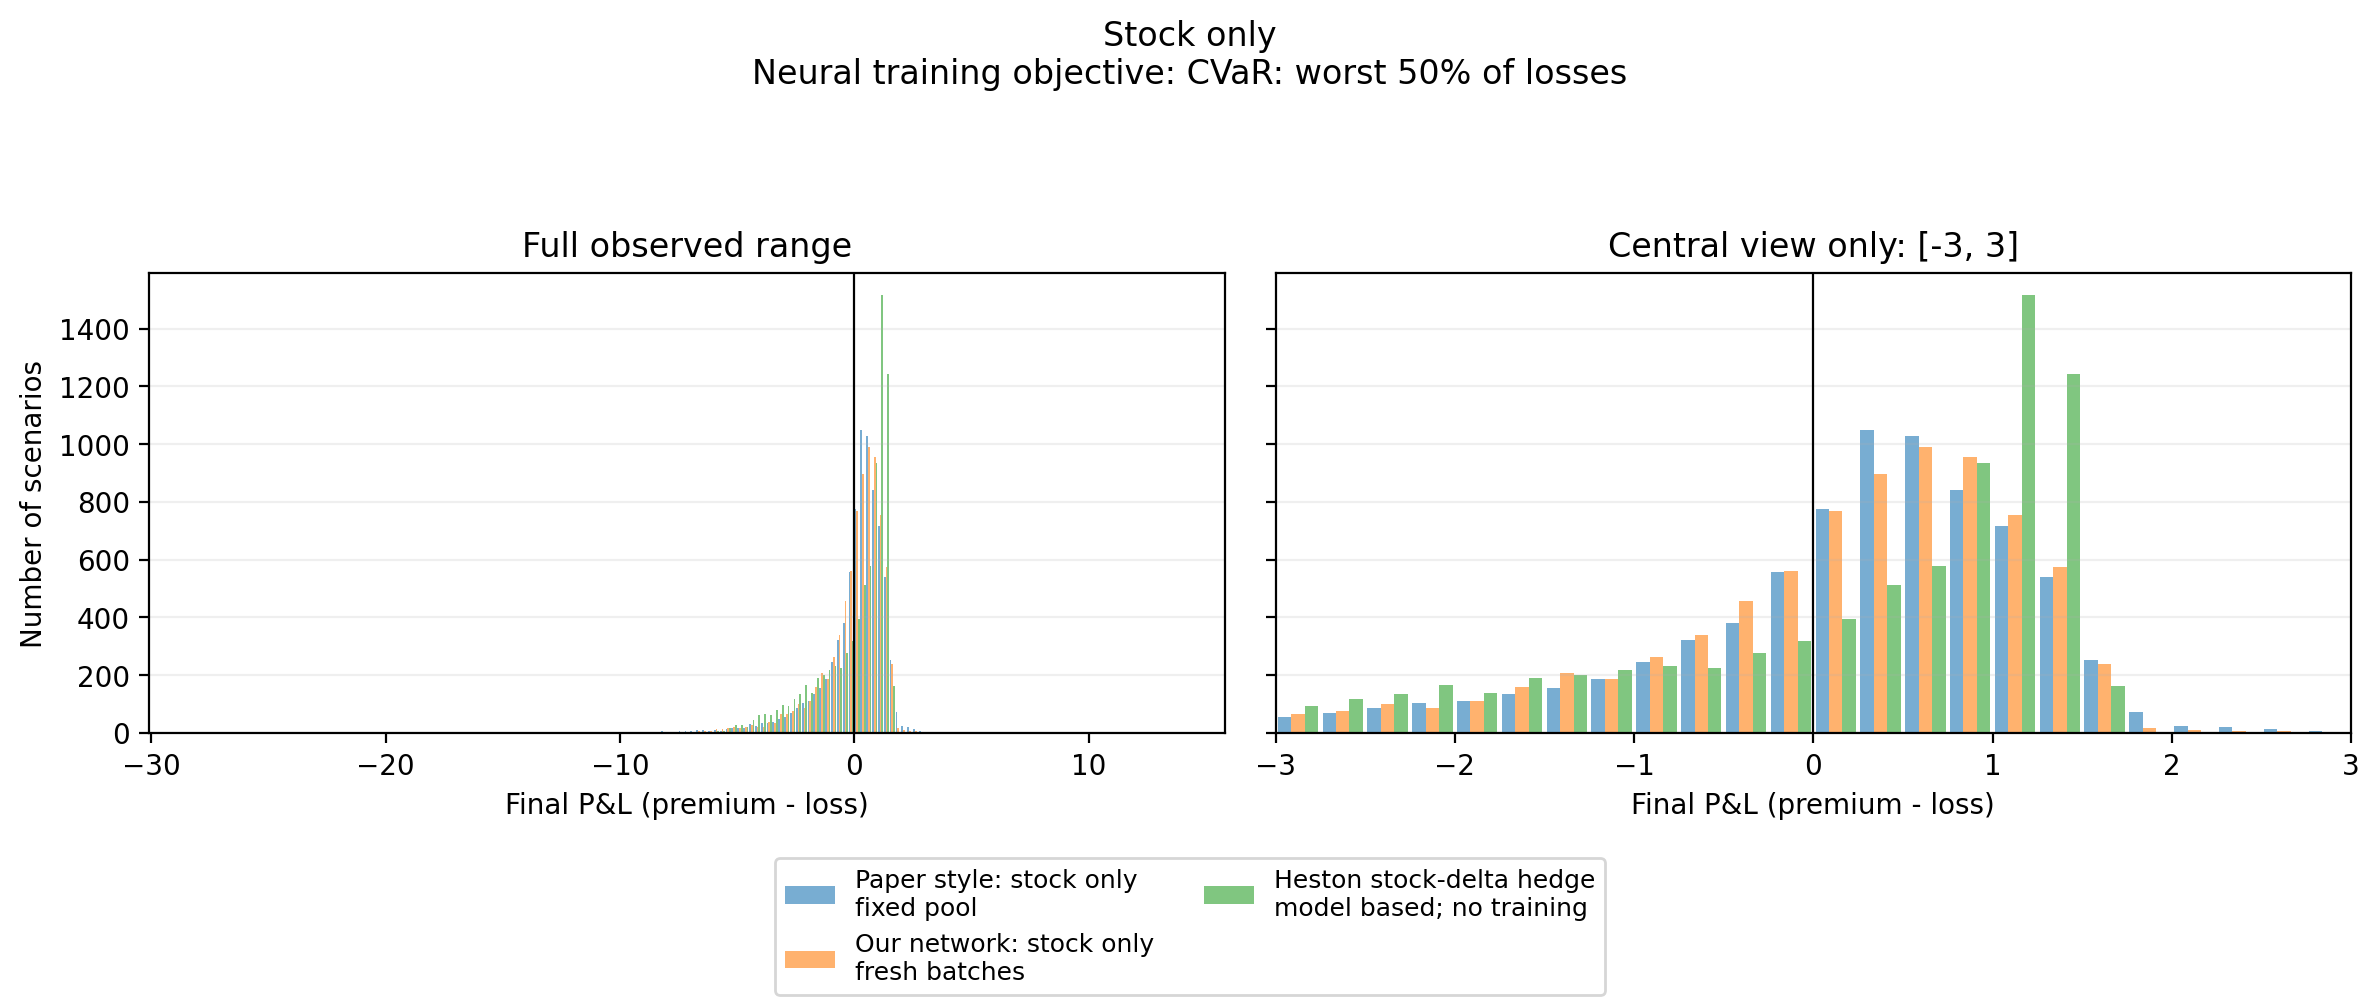


Stock only: CVaR of terminal loss
Paper style: stock only: 2.680726
Our network: stock only: 2.622599
Heston benchmark: 2.803245


In [19]:
from scripts.general_nn import call_price
from scripts import plots

# Use the same premium for every strategy.
premium = call_price(ours.settings)

# Compare each network against a Heston hedge with the same instruments.
comparisons = [
    (control, ours, "Stock only"),
    (paper, ours_variance, "Stock + variance claim"),
]

reference, other, title = comparisons[0]
# Compute and store the Heston benchmark on the existing test paths.
reference.evaluate(include_heston=True)

# Explicitly include its P&L distribution in the figure.
plots.plot_pnl_comparison(
    [reference, other],
    premium=premium,
    objective="CVaR",
    title=title,
    include_heston=True,
)

# Print numerical comparisons as well as showing the histogram.
print(f"\n{title}: CVaR of terminal loss")
for model in (reference, other):
    score = model.get_run("CVaR", replicate=0)["metrics"]["cvar"]
    print(f"{model.name}: {score:.6f}")

score = reference.benchmarks["heston"]["cvar"]
print(f"Heston benchmark: {score:.6f}")


## Stock and Variance Claim P&L Histogram

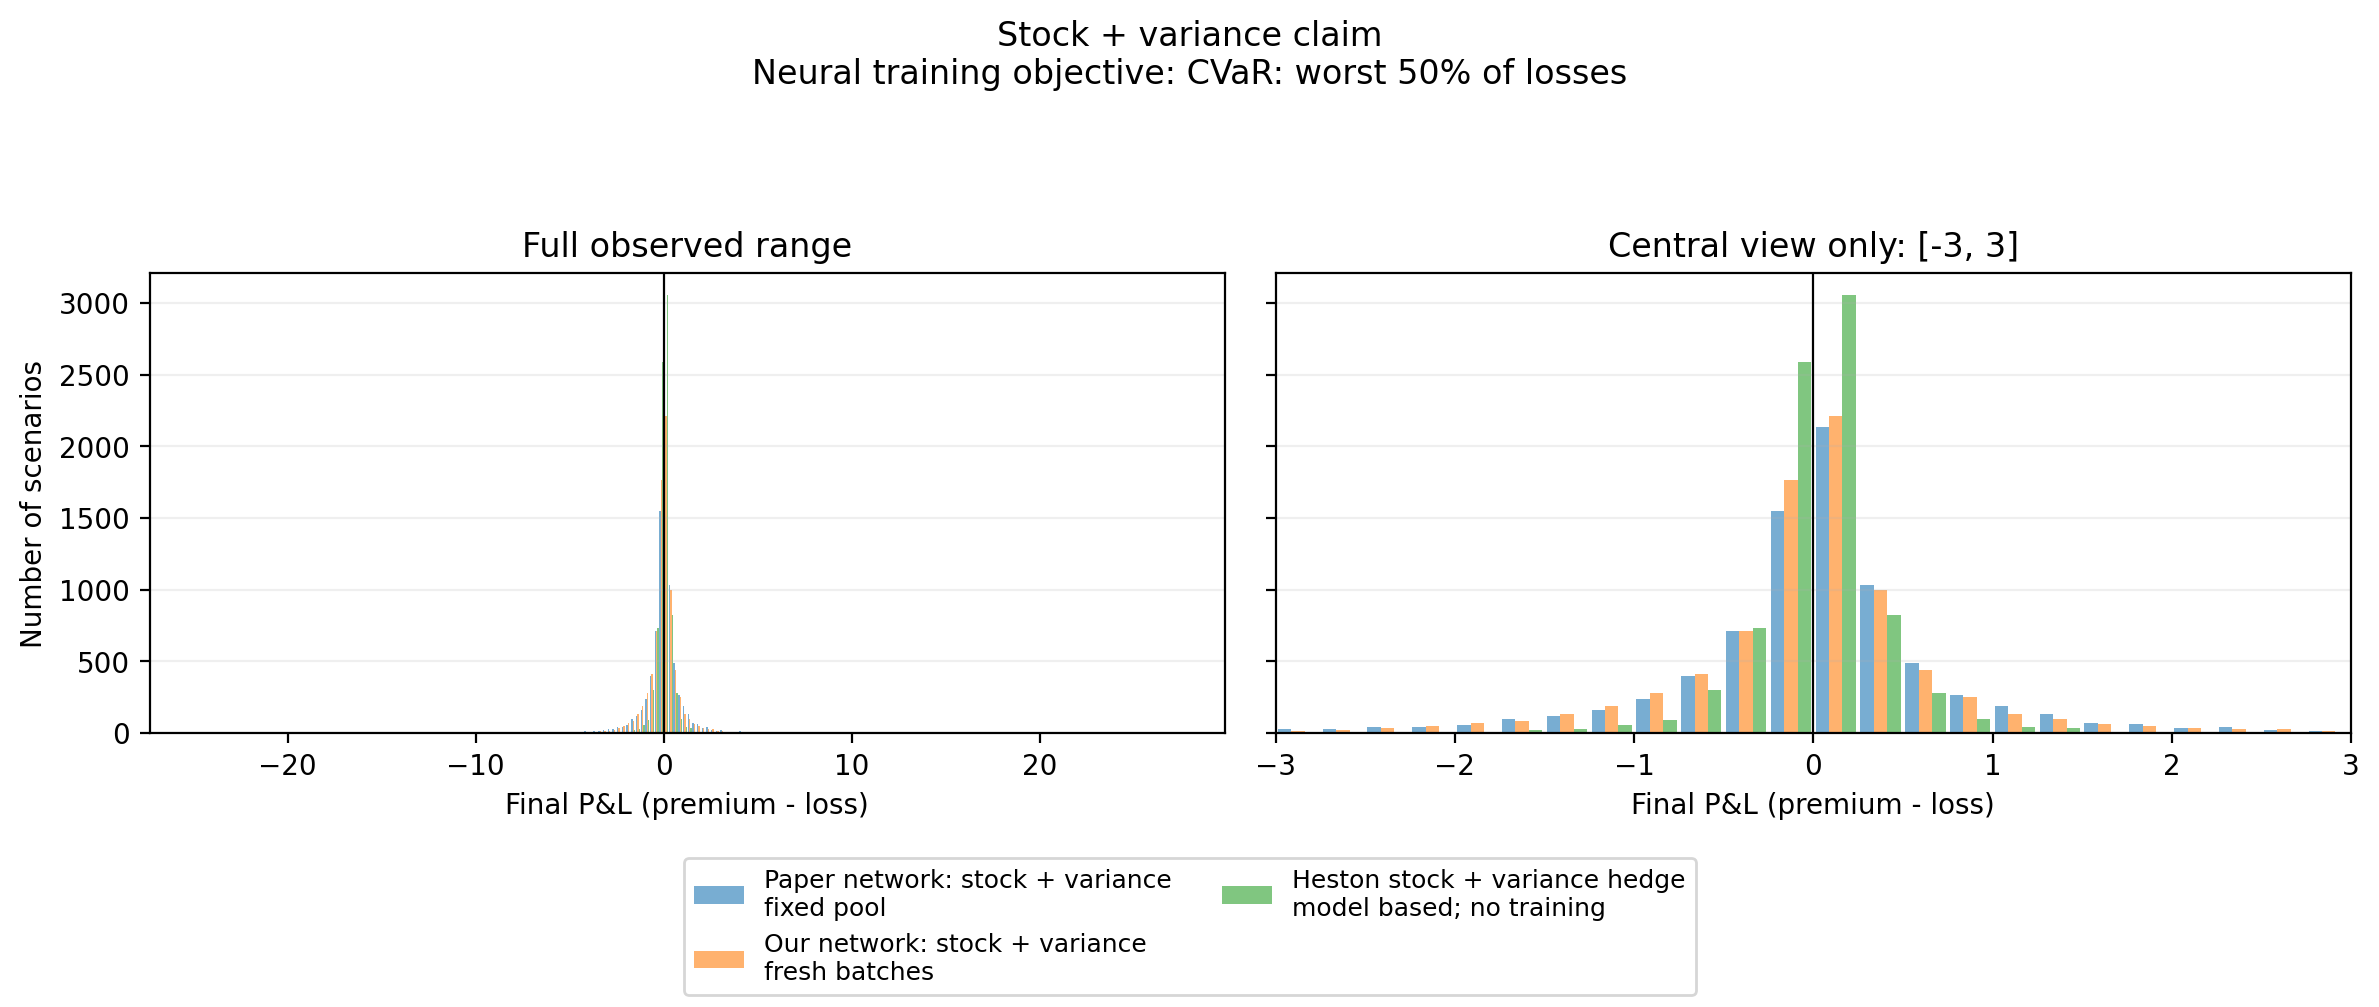


Stock + variance claim: CVaR of terminal loss
Paper network: stock + variance: 2.331159
Our network: stock + variance: 2.199188
Heston benchmark: 1.925640


In [20]:
reference, other, title = comparisons[1]
# Compute and store the Heston benchmark on the existing test paths.
reference.evaluate(include_heston=True)

# Explicitly include its P&L distribution in the figure.
plots.plot_pnl_comparison(
    [reference, other],
    premium=premium,
    objective="CVaR",
    title=title,
    include_heston=True,
)

# Print numerical comparisons as well as showing the histogram.
print(f"\n{title}: CVaR of terminal loss")
for model in (reference, other):
    score = model.get_run("CVaR", replicate=0)["metrics"]["cvar"]
    print(f"{model.name}: {score:.6f}")

score = reference.benchmarks["heston"]["cvar"]
print(f"Heston benchmark: {score:.6f}")


## Comments: P&L for stock and variance

All three strategies can now trade both stock and the variance claim. The Heston benchmark uses model sensitivities rather than neural-network training, with the same trading dates and transaction-cost accounting.

In this saved run, Heston has the lowest CVaR loss: 2.141, followed by our network at 2.359 and the paper-style network at 2.634. Our network improves on the paper-style implementation but does not beat Heston in this comparison.

These are preliminary results from one short training run. Longer training and repeated runs are needed to assess how stable the differences are.
